# Clase 8 · Autoevaluación: Segmentación de clientes con K-Means
**Materia:** Aprendizaje Automático (2026) — Centro Politécnico Superior Malvinas Argentinas
**Alumno:** David Moreira

**Objetivo:** identificar cuántos segmentos latentes de clientes existen a partir de su comportamiento de compra y uso del sitio, **sin etiquetas **previas** (aprendizaje no supervisado), y describir el perfil de cada segmento a partir de sus centroides.

Sigo el flujo de trabajo visto: *pregunta → obtener datos → explorar y preparar → modelar → comunicar resultados*.

## 1. Librerías

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 20)
SEMILLA = 42   # semilla fija para que los resultados sean reproducibles

## 2. Obtener los datos (`read_csv`)

In [2]:
df = pd.read_csv('dataset_segmentacion_clientes.csv')
print(df.shape)
df.head()

(700, 7)


,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,noise_gauss,noise_uniform
0,11.152508,181.300834,33.564036,1.000000,0.800000,-1.806578,-2.516905
1,12.053451,178.637272,35.432081,0.784974,0.000000,0.645129,2.115460
2,2.203006,450.185298,7.030757,0.898297,0.000000,-0.047406,-0.724173
3,4.233314,89.006342,10.834453,0.000000,0.800000,0.901700,-2.974026
4,1.716799,449.773982,7.254548,0.000000,0.003279,0.386013,2.424522


## 3. Inspección de los datos (`info`, `describe`, `isna`, `duplicated`)
Antes de transformar, reviso tipos, rangos, faltantes y duplicados.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 700 entries, 0 to 699
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   purchase_freq_month   700 non-null    float64
 1   avg_basket_usd        700 non-null    float64
 2   time_on_site_min      700 non-null    float64
 3   discount_sensitivity  700 non-null    float64
 4   returns_rate          700 non-null    float64
 5   noise_gauss           700 non-null    float64
 6   noise_uniform         700 non-null    float64
dtypes: float64(7)
memory usage: 38.4 KB


In [4]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
purchase_freq_month,700.0,5.876,4.471,0.100,2.278,4.135,11.215,14.603
avg_basket_usd,700.0,248.173,154.904,86.994,90.767,180.224,449.719,452.974
time_on_site_min,700.0,16.785,12.914,3.163,6.604,9.974,34.341,38.348
discount_sensitivity,700.0,0.425,0.431,0.000,0.000,0.296,1.000,1.000
returns_rate,700.0,0.337,0.357,0.000,0.000,0.166,0.800,0.800
noise_gauss,700.0,0.024,1.009,-3.566,-0.654,0.077,0.728,2.863
noise_uniform,700.0,-0.011,1.680,-2.994,-1.425,0.013,1.407,2.995


In [5]:
print('Valores faltantes por columna:')
print(df.isna().sum())
print('\nFilas duplicadas:', df.duplicated().sum())

Valores faltantes por columna:
purchase_freq_month     0
avg_basket_usd          0
time_on_site_min        0
discount_sensitivity    0
returns_rate            0
noise_gauss             0
noise_uniform           0
dtype: int64

Filas duplicadas: 0


**Observación importante:** el CSV trae **7 columnas**, pero la consigna describe solo **5 variables de comportamiento**.
Las columnas `noise_gauss` y `noise_uniform`, por su nombre y por sus estadísticas (media ≈ 0, sin significado de negocio), parecen ser **ruido agregado a propósito** (gaussiano y uniforme).

No las uso para segmentar: no describen ningún comportamiento del cliente y, como K-Means trabaja con distancias, solo agregarían dimensiones que “diluyen” la estructura real. En la sección 6 lo compruebo empíricamente.

In [6]:
variables = ['purchase_freq_month', 'avg_basket_usd', 'time_on_site_min',
             'discount_sensitivity', 'returns_rate']
ruido = ['noise_gauss', 'noise_uniform']

# Reglas de calidad conocidas (Clase 3): rangos posibles según la consigna
print('Frecuencia negativa:', (df.purchase_freq_month < 0).sum())
print('Ticket <= 0:', (df.avg_basket_usd <= 0).sum())
print('Tiempo negativo:', (df.time_on_site_min < 0).sum())
print('Sensibilidad fuera de [0,1]:', (~df.discount_sensitivity.between(0, 1)).sum())
print('Devoluciones fuera de [0,0.8]:', (~df.returns_rate.between(0, 0.8)).sum())

Frecuencia negativa: 0
Ticket <= 0: 0
Tiempo negativo: 0
Sensibilidad fuera de [0,1]: 0
Devoluciones fuera de [0,0.8]: 0


### 3.1 Visualización (Matplotlib)

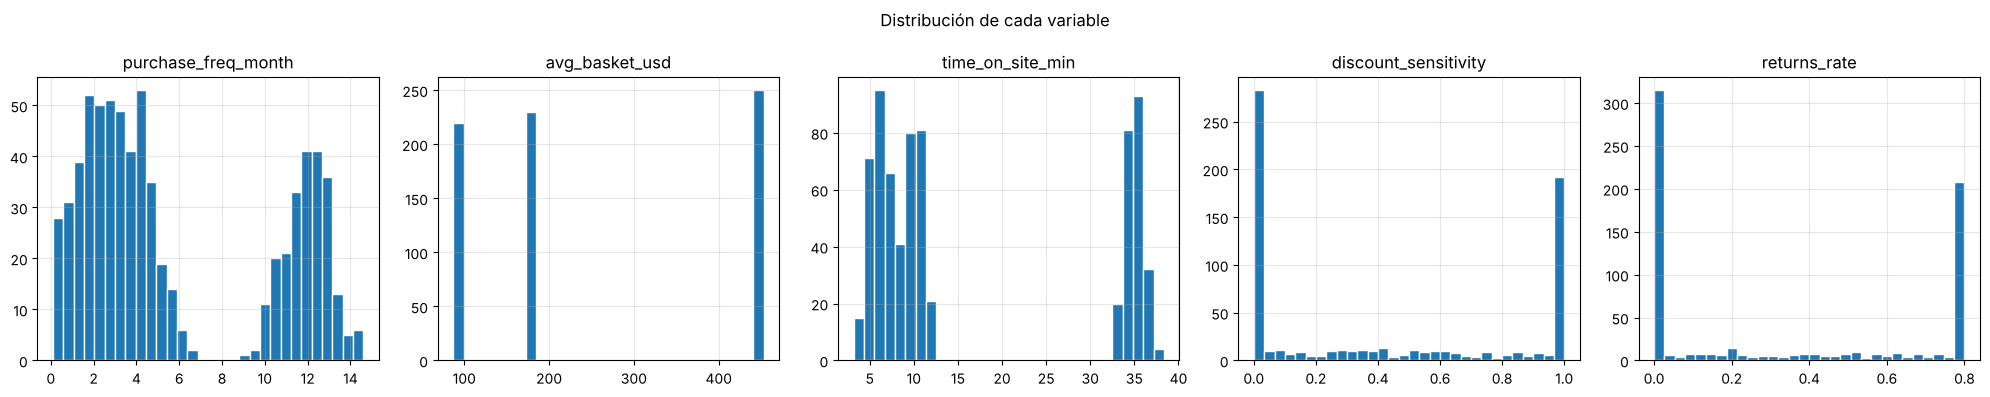

In [7]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, variables):
    ax.hist(df[col], bins=30, color='C0', edgecolor='white')
    ax.set_title(col)
    ax.grid(alpha=0.3)
fig.suptitle('Distribución de cada variable')
plt.tight_layout(); plt.show()

Los histogramas no son unimodales: se ven **varios “picos” separados**, una primera pista de que existen grupos de clientes diferenciados.

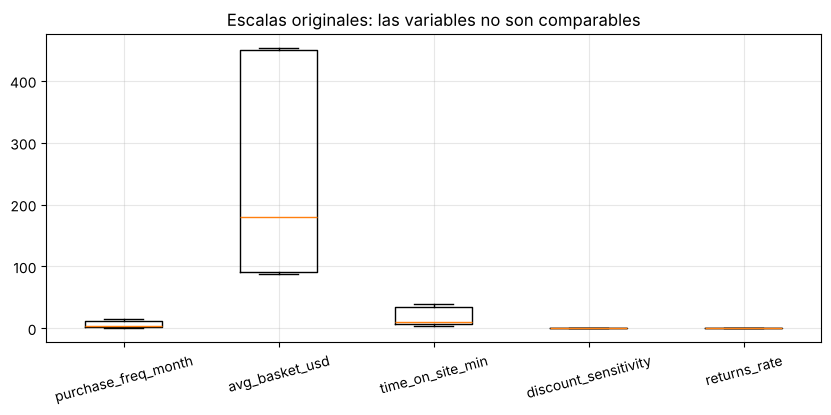

In [8]:
plt.figure(figsize=(10, 4))
plt.boxplot([df[c] for c in variables], tick_labels=variables)
plt.title('Escalas originales: las variables no son comparables')
plt.xticks(rotation=15); plt.grid(alpha=0.3); plt.show()

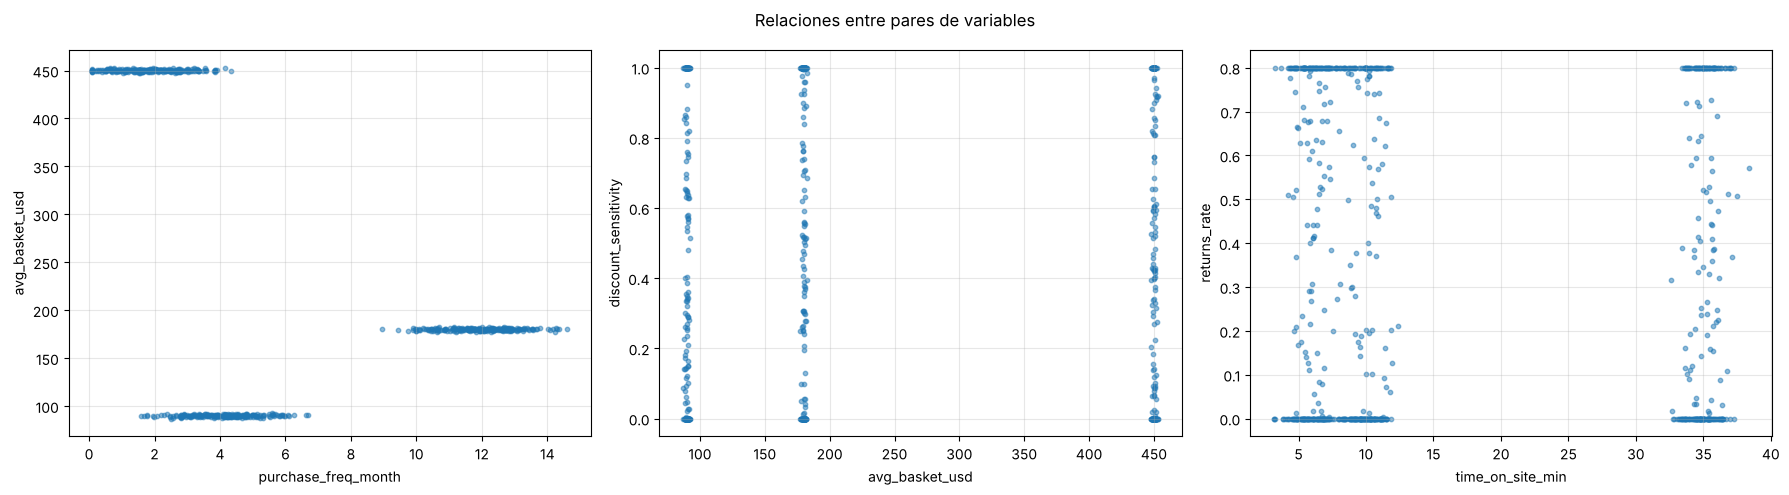

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
pares = [('purchase_freq_month', 'avg_basket_usd'),
         ('avg_basket_usd', 'discount_sensitivity'),
         ('time_on_site_min', 'returns_rate')]
for ax, (x, y) in zip(axes, pares):
    ax.scatter(df[x], df[y], s=10, alpha=0.5)
    ax.set_xlabel(x); ax.set_ylabel(y); ax.grid(alpha=0.3)
fig.suptitle('Relaciones entre pares de variables')
plt.tight_layout(); plt.show()

## 4. Preparación: escalado 
Como indica la pista de la consigna, hay que escalar. `avg_basket_usd` va aprox. de 87 a 453, mientras que `discount_sensitivity` va de 0 a 1. K-Means usa **distancia euclídea**, así que sin escalar el ticket dominaría el cálculo solo por sus unidades, no por su importancia.

Elijo **`StandardScaler`** (media 0, desviación 1) porque es el escalado más habitual antes de K-Means.
No separo train/test: en clustering no hay variable objetivo que predecir, y el objetivo es describir **todos** los clientes. Igualmente uso `fit_transform` sobre el mismo conjunto que se segmenta.

In [10]:
escalador = StandardScaler()
X = escalador.fit_transform(df[variables])

pd.DataFrame(X, columns=variables).describe().T[['mean', 'std', 'min', 'max']].round(3)

,mean,std,min,max
purchase_freq_month,-0.0,1.001,-1.293,1.953
avg_basket_usd,-0.0,1.001,-1.041,1.323
time_on_site_min,0.0,1.001,-1.056,1.671
discount_sensitivity,0.0,1.001,-0.986,1.333
returns_rate,-0.0,1.001,-0.946,1.299


## 5. Elección de k: método del codo (k = 2..6)
Para cada k entreno K-Means y guardo la **inercia** (suma de distancias al cuadrado de cada punto a su centroide). Uso `init='k-means++'` y `n_init=10` para reducir el riesgo de quedar en un mínimo local.

Como complemento agrego el **coeficiente de silueta** (lo uso solo como segunda opinión: va de -1 a 1 y cuanto más alto, mejor separados los grupos).

In [11]:
ks = range(2, 7)
inercias, siluetas = [], []
for k in ks:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=SEMILLA)
    etiquetas = km.fit_predict(X)
    inercias.append(km.inertia_)
    siluetas.append(silhouette_score(X, etiquetas))

tabla_k = pd.DataFrame({'k': list(ks), 'inercia': inercias, 'silueta': siluetas})
tabla_k['caida_inercia'] = -tabla_k['inercia'].diff()
tabla_k.round(3)

,k,inercia,silueta,caida_inercia
0,2,2088.881,0.400,NaN
1,3,1408.702,0.431,680.179
2,4,1173.438,0.429,235.264
3,5,997.742,0.420,175.696
4,6,762.466,0.461,235.276


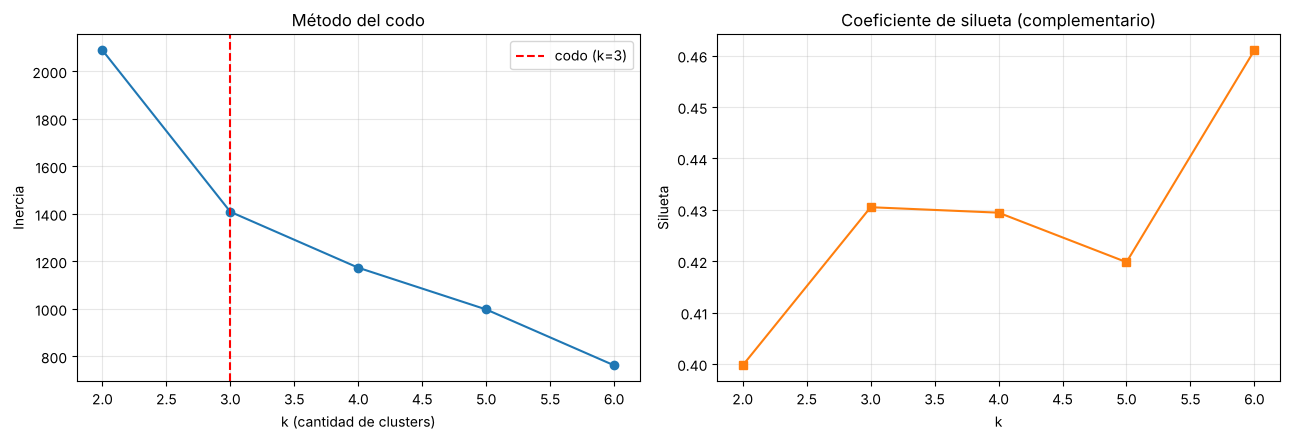

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(ks), inercias, 'o-')
axes[0].axvline(3, color='red', ls='--', label='codo (k=3)')
axes[0].set_xlabel('k (cantidad de clusters)'); axes[0].set_ylabel('Inercia')
axes[0].set_title('Método del codo'); axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(list(ks), siluetas, 's-', color='C1')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Silueta')
axes[1].set_title('Coeficiente de silueta (complementario)'); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Interpretación del codo:** la caída de inercia de k=2 a k=3 es la más grande (≈680). A partir de k=3 la curva baja casi en línea recta (≈200–235 por cada k extra): agregar clusters ya no da una mejora “desproporcionada”. Por eso el **codo está en k = 3**.

La silueta es similar entre k=3 y k=6 (6 queda apenas arriba), lo que sugiere que dentro de los 3 grupos grandes existen **subgrupos**. Lo analizo en la sección 8.

## 6. Comprobación: ¿qué pasa si incluyo las columnas de ruido?

In [13]:
X_con_ruido = StandardScaler().fit_transform(df[variables + ruido])
comparacion = []
for k in ks:
    sil_5 = silhouette_score(X, KMeans(k, n_init=10, random_state=SEMILLA).fit_predict(X))
    sil_7 = silhouette_score(X_con_ruido, KMeans(k, n_init=10, random_state=SEMILLA).fit_predict(X_con_ruido))
    comparacion.append((k, sil_5, sil_7))
pd.DataFrame(comparacion, columns=['k', 'silueta 5 variables', 'silueta con ruido']).round(3)

,k,silueta 5 variables,silueta con ruido
0,2,0.400,0.288
1,3,0.431,0.279
2,4,0.429,0.252
3,5,0.420,0.227
4,6,0.461,0.242


Con las columnas de ruido la silueta baja en todos los k. Esto confirma la decisión de **excluirlas**: el ruido no aporta estructura y empeora la separación (efecto relacionado con la “maldición de la dimensionalidad”).

## 7. Modelo final con k = 3 y análisis de centroides

In [14]:
k_final = 3
kmeans = KMeans(n_clusters=k_final, init='k-means++', n_init=10, max_iter=2000, random_state=SEMILLA)
df['cluster'] = kmeans.fit_predict(X)

# Centroides llevados a la escala original para poder interpretarlos
centroides = pd.DataFrame(escalador.inverse_transform(kmeans.cluster_centers_), columns=variables)
centroides['n_clientes'] = df['cluster'].value_counts().sort_index()
centroides['%'] = (centroides['n_clientes'] / len(df) * 100).round(1)
centroides.round(2)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,n_clientes,%
0,11.96,180.00,35.02,0.54,0.33,230,32.9
1,1.85,450.12,5.97,0.36,0.38,250,35.7
2,4.09,89.96,10.00,0.38,0.30,220,31.4


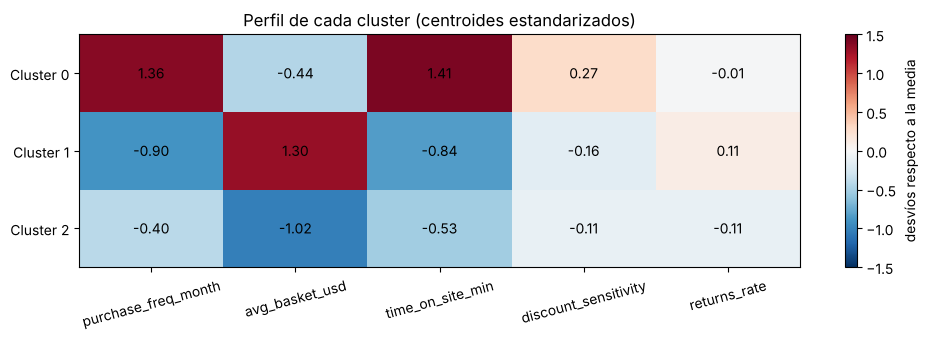

In [15]:
# Centroides en escala estandarizada: >0 = por encima del promedio, <0 = por debajo
cent_z = pd.DataFrame(kmeans.cluster_centers_, columns=variables)
plt.figure(figsize=(10, 3.5))
plt.imshow(cent_z, cmap='RdBu_r', vmin=-1.5, vmax=1.5, aspect='auto')
plt.colorbar(label='desvíos respecto a la media')
plt.xticks(range(len(variables)), variables, rotation=15)
plt.yticks(range(k_final), [f'Cluster {i}' for i in range(k_final)])
for i in range(k_final):
    for j in range(len(variables)):
        plt.text(j, i, f'{cent_z.iloc[i, j]:.2f}', ha='center', va='center')
plt.title('Perfil de cada cluster (centroides estandarizados)')
plt.tight_layout(); plt.show()

Varianza explicada por las 2 componentes: 0.672


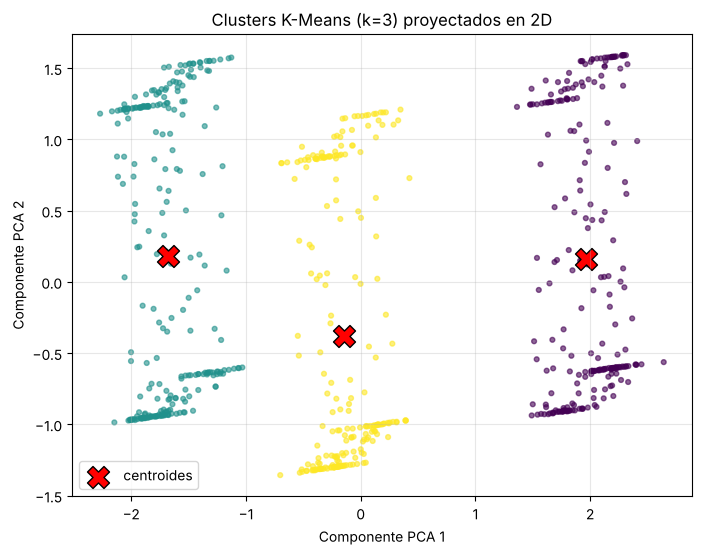

In [16]:
# Visualización 2D con PCA: solo para graficar, el clustering se hizo con las 5 variables
pca = PCA(n_components=2, random_state=SEMILLA)
X_2d = pca.fit_transform(X)
cent_2d = pca.transform(kmeans.cluster_centers_)
print('Varianza explicada por las 2 componentes:', pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(8, 6))
plt.scatter(X_2d[:, 0], X_2d[:, 1], c=df['cluster'], cmap='viridis', s=12, alpha=0.6)
plt.scatter(cent_2d[:, 0], cent_2d[:, 1], c='red', marker='X', s=250, edgecolor='k', label='centroides')
plt.xlabel('Componente PCA 1'); plt.ylabel('Componente PCA 2')
plt.title('Clusters K-Means (k=3) proyectados en 2D'); plt.legend(); plt.grid(alpha=0.3); plt.show()

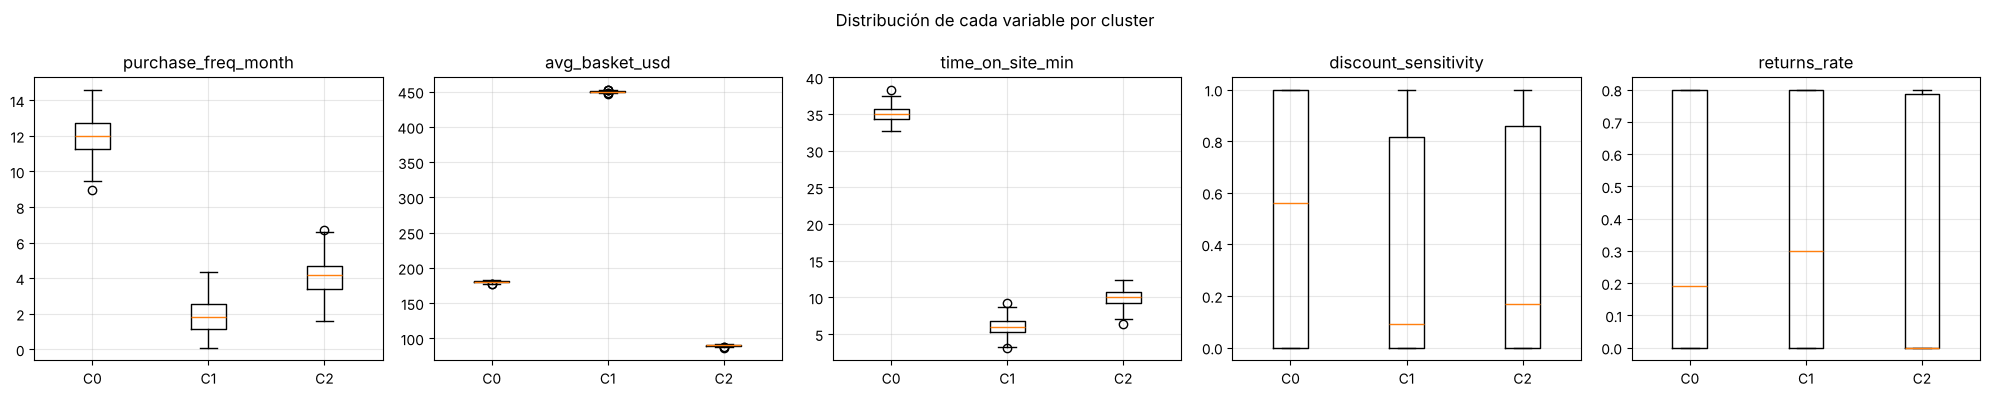

In [17]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, variables):
    ax.boxplot([df.loc[df.cluster == c, col] for c in range(k_final)],
               tick_labels=[f'C{c}' for c in range(k_final)])
    ax.set_title(col); ax.grid(alpha=0.3)
fig.suptitle('Distribución de cada variable por cluster')
plt.tight_layout(); plt.show()

### Descripción de los perfiles (k = 3)
Valores aproximados de los centroides en escala original (ver tabla anterior):

| Cluster | Frecuencia/mes | Ticket USD | Tiempo en sitio | Sens. descuento | Devoluciones | Clientes | Perfil |
|---|---|---|---|---|---|---|---|
| **0** | ≈12 (alta) | ≈180 (medio) | ≈35 min (alto) | ≈0.54 (media) | ≈0.33 | 230 (32.9%) | **Compradores frecuentes y exploradores** |
| **1** | ≈1.9 (baja) | ≈450 (alto) | ≈6 min (bajo) | ≈0.36 | ≈0.38 | 250 (35.7%) | **Compradores esporádicos de ticket alto** |
| **2** | ≈4 (media-baja) | ≈90 (bajo) | ≈10 min | ≈0.38 | ≈0.30 | 220 (31.4%) | **Compradores ocasionales de ticket bajo** |

- **Cluster 0 – Frecuentes / exploradores:** compran muy seguido, pasan mucho tiempo en el sitio y gastan un ticket medio. *Acción sugerida:* programas de fidelización y promociones recurrentes.
- **Cluster 1 – Esporádicos premium:** compran poco pero con el ticket más alto y entran al sitio a comprar rápido (poco tiempo de navegación). Coincide con el patrón de la consigna “frecuencia baja pero ticket alto”. *Acción sugerida:* upselling premium y experiencia de compra ágil.
- **Cluster 2 – Ocasionales de ticket bajo:** frecuencia y gasto bajos. *Acción sugerida:* campañas de activación para aumentar frecuencia o ticket.

**Lo que NO aparece con k=3 (resultado honesto):** la sensibilidad a descuentos y la tasa de devoluciones tienen promedios parecidos en los tres clusters (≈0.3–0.5). Es decir, con k=3 esas dos variables no diferencian los segmentos; los grupos se separan principalmente por **frecuencia, ticket y tiempo en sitio**. Por eso el patrón “ticket alto + baja sensibilidad” de la consigna se cumple solo en parte: el ticket alto sí, la baja sensibilidad no (es media).

## 8. Análisis complementario: k = 6
La silueta sugería que podía haber más estructura. Pruebo k=6 para ver si los 3 segmentos se dividen en subgrupos con sentido de negocio.

In [18]:
km6 = KMeans(n_clusters=6, init='k-means++', n_init=10, random_state=SEMILLA)
df['cluster_k6'] = km6.fit_predict(X)
cent6 = pd.DataFrame(escalador.inverse_transform(km6.cluster_centers_), columns=variables)
cent6['n_clientes'] = df['cluster_k6'].value_counts().sort_index()
cent6.sort_values('avg_basket_usd').round(2)

,purchase_freq_month,avg_basket_usd,time_on_site_min,discount_sensitivity,returns_rate,n_clientes
5,4.23,89.88,10.05,0.35,0.73,84
0,4.01,90.01,9.97,0.40,0.03,136
1,11.95,179.99,35.13,0.11,0.35,110
4,11.97,180.00,34.92,0.93,0.31,120
3,1.81,450.05,6.08,0.35,0.73,122
2,1.88,450.19,5.87,0.36,0.04,128


In [19]:
pd.crosstab(df['cluster'], df['cluster_k6'], rownames=['k=3'], colnames=['k=6'])

k=6,0,1,2,3,4,5
k=3,,,,,,
0,0,110,0,0,120,0
1,0,0,128,122,0,0
2,136,0,0,0,0,84


**Interpretación de k = 6:** la tabla cruzada muestra que k=6 **no inventa grupos nuevos**: cada uno de los 3 clusters se divide exactamente en 2 subgrupos.

- El **cluster 0 (frecuentes)** se divide por **sensibilidad a descuentos**: ≈0.93 (muy sensibles, 120 clientes) vs. ≈0.11 (poco sensibles, 110). El primer subgrupo es el más cercano al patrón de la consigna *“frecuencia alta y alta sensibilidad a descuentos”* → foco para promociones; el segundo compra seguido aun sin descuentos.
- El **cluster 1 (premium)** y el **cluster 2 (ticket bajo)** se dividen por **tasa de devoluciones**: ≈0.73 (devuelven mucho) vs. ≈0.03–0.04 (casi no devuelven). Esto responde al patrón de devoluciones diferenciadas que pedía la consigna. Dentro de cada par, el tiempo en sitio es prácticamente igual, por lo que **no se observa** la relación “exploran más → devuelven más”.

Entonces hay dos lecturas válidas según el uso:
- **k = 3** (justificado por el codo): segmentación general, simple de comunicar.
- **k = 6** (mejor silueta, 0.461): segmentación más fina, útil para acciones específicas (promociones dirigidas o políticas de devoluciones).

## 9. Conclusiones
1. **Preparación:** el dataset no tenía faltantes, duplicados ni valores fuera de rango. Excluí `noise_gauss` y `noise_uniform` porque no son variables de comportamiento y comprobé que empeoran la separación. Estandaricé con `StandardScaler` porque K-Means depende de distancias y las escalas eran muy distintas.
2. **Cantidad de segmentos:** según el **método del codo**, el valor razonable es **k = 3**: la mayor caída de inercia ocurre de 2 a 3 clusters y luego la curva baja de forma casi lineal.
3. **Perfiles:** los 3 segmentos se diferencian por frecuencia, ticket y tiempo en sitio: *frecuentes/exploradores*, *esporádicos de ticket alto* y *ocasionales de ticket bajo*.
4. **Estructura más fina:** con k = 6 cada segmento se divide en dos según sensibilidad a descuentos (frecuentes) o tasa de devoluciones (premium y ticket bajo). La silueta es algo mayor en k = 6, así que la elección depende del objetivo del negocio.
5. **Limitaciones:** K-Means asume grupos aproximadamente esféricos y de varianza parecida, y el resultado depende de la inicialización (por eso fijé `random_state` y usé `n_init=10`). Los nombres de los segmentos son interpretaciones mías a partir de los centroides, no etiquetas reales: habría que validarlos con información del negocio.